In [ ]:
!pip install -q tensorflow tensorflow-hub

In [ ]:
import numpy as np
from sklearn.metrics.pairwise import cosine_similarity
import tensorflow as tf
import tensorflow_hub as hub

## Пример по шагам

### Шаг 1: Кодируем в эмбеддинги референтный корпус запросов

In [ ]:
texts = [
    "купить iPhone недорого",
    "продажа айфонов б/у",
    "цена на смартфон Apple",
    "рецепт пиццы с грибами",
    "как приготовить пиццу дома",
    "итальянская пицца рецепт",
    "погода в Москве сегодня",
    "прогноз погоды в столице",
    "курс доллара к рублю",
    "обмен валюты USD RUB"
]

In [ ]:
elmo = hub.load("https://tfhub.dev/google/elmo/3")
inputs = tf.constant(texts)
outputs = elmo.signatures["default"](inputs)["elmo"]
word_embeddings = outputs.numpy()

In [ ]:
word_embeddings.shape # Количество предложений в батче, максимальная длина предложения, длина эмбеддинга

(10, 4, 1024)

In [ ]:
sentence_embeddings = np.mean(word_embeddings, axis = 1)

In [ ]:
sentence_embeddings.shape # Количество предложений в батче, длина эмбеддинга

(10, 1024)

### Шаг 2. Делаем поисковый запрос и кодируем его в эмбеддинг

In [ ]:
query = "куплю телефон недорого"
inputs_q = tf.constant([query])
outputs_q = elmo.signatures["default"](inputs_q)["elmo"]
query_emb = np.mean(outputs_q.numpy(), axis = 1)

In [ ]:
query_emb.shape # Количество предложений в батче, длина эмбеддинга

(1, 1024)

### Шаг 3. Считаем косинусную близость и сортируем фразы по возрастанию

In [ ]:
cs = cosine_similarity(query_emb, sentence_embeddings)

In [ ]:
cs

array([[0.7607895 , 0.82097054, 0.67782325, 0.7836032 , 0.8005444 ,
        0.78506935, 0.7922051 , 0.79555845, 0.74233514, 0.7270925 ]],
      dtype=float32)

In [ ]:
for i in cs.argsort()[0].tolist():
  print(texts[i], "похожесть: ", cs[0][i]  )

цена на смартфон Apple похожесть:  0.67782325
обмен валюты USD RUB похожесть:  0.7270925
курс доллара к рублю похожесть:  0.74233514
купить iPhone недорого похожесть:  0.7607895
рецепт пиццы с грибами похожесть:  0.7836032
итальянская пицца рецепт похожесть:  0.78506935
погода в Москве сегодня похожесть:  0.7922051
прогноз погоды в столице похожесть:  0.79555845
как приготовить пиццу дома похожесть:  0.8005444
продажа айфонов б/у похожесть:  0.82097054


## Пример 1. Поисковик

Задаем класс

In [ ]:
class SemanticSearchEngine:
    def __init__(self):
        self.elmo = hub.load("https://tfhub.dev/google/elmo/3")
        self.queries = []
        self.embeddings = None

    def add_queries(self, queries):
        """Добавление поисковых запросов в базу"""
        self.queries = queries
        self.embeddings = self._get_embeddings(queries)

    def _get_embeddings(self, texts):
        """Получение эмбеддингов для списка текстов"""
        inputs = tf.constant(texts)
        outputs = self.elmo.signatures["default"](inputs)
        token_embeddings = outputs["elmo"].numpy()
        sentence_embeddings = np.mean(token_embeddings, axis=1)
        return sentence_embeddings

    def search(self, query, top_k=3):
        """Поиск похожих запросов"""
        query_embedding = self._get_embeddings([query])[0]
        similarities = cosine_similarity([query_embedding], self.embeddings)[0]
        results = list(zip(self.queries, similarities))
        results.sort(key=lambda x: x[1], reverse=True)
        return results[:top_k]

Пример использования

In [ ]:
search_engine = SemanticSearchEngine()

In [ ]:
# База поисковых запросов (например, из истории или популярных запросов)
search_queries = [
    "купить iPhone недорого",
    "продажа айфонов б/у",
    "цена на смартфон Apple",
    "рецепт пиццы с грибами",
    "как приготовить пиццу дома",
    "итальянская пицца рецепт",
    "погода в Москве сегодня",
    "прогноз погоды в столице",
    "курс доллара к рублю",
    "обмен валюты USD RUB"
]

search_engine.add_queries(search_queries)

In [ ]:
search_engine.queries

['купить iPhone недорого',
 'продажа айфонов б/у',
 'цена на смартфон Apple',
 'рецепт пиццы с грибами',
 'как приготовить пиццу дома',
 'итальянская пицца рецепт',
 'погода в Москве сегодня',
 'прогноз погоды в столице',
 'курс доллара к рублю',
 'обмен валюты USD RUB']

In [ ]:
search_engine.embeddings.shape

(10, 1024)

In [ ]:
test_queries = [
    "где купить айфон дешево",
    "приготовление пиццы с сыром",
    "какая погода в москве"
]

print("=== СЕМАНТИЧЕСКИЙ ПОИСК ПО ЗАПРОСАМ ===\n")

for query in test_queries:
    print(f"Поиск для: '{query}'")
    results = search_engine.search(query)
    for i, (found_query, similarity) in enumerate(results):
        print(f"  {i+1}. {found_query} (схожесть: {similarity:.4f})")
    print()

=== СЕМАНТИЧЕСКИЙ ПОИСК ПО ЗАПРОСАМ ===

Поиск для: 'где купить айфон дешево'
  1. продажа айфонов б/у (схожесть: 0.8160)
  2. как приготовить пиццу дома (схожесть: 0.7975)
  3. прогноз погоды в столице (схожесть: 0.7875)

Поиск для: 'приготовление пиццы с сыром'
  1. рецепт пиццы с грибами (схожесть: 0.8921)
  2. как приготовить пиццу дома (схожесть: 0.8233)
  3. прогноз погоды в столице (схожесть: 0.8022)

Поиск для: 'какая погода в москве'
  1. погода в Москве сегодня (схожесть: 0.9074)
  2. прогноз погоды в столице (схожесть: 0.8447)
  3. как приготовить пиццу дома (схожесть: 0.8014)



## Попробуем для английских фраз

In [ ]:
search_engine = SemanticSearchEngine()

search_queries = [
    "purchase cheap iphone",
    "used mobiles sale",
    "iphone price",
    "mushroom pizza recipe",
    "how to make pizza at home",
    "italian pizza recipe",
    "weather in Moscow today",
    "weather forecast in the capital",
    "dollar to ruble exchange rate",
    "currency exchange USD to RUR"
]

search_engine.add_queries(search_queries)

test_queries = [
    "where to buy a cheap iphone",
    "make cheese pizza",
    "weather in Moscow tomorrow"
]

print("=== СЕМАНТИЧЕСКИЙ ПОИСК ПО ЗАПРОСАМ ===\n")

for query in test_queries:
    print(f"Поиск для: '{query}'")
    results = search_engine.search(query)
    for i, (found_query, similarity) in enumerate(results):
        print(f"  {i+1}. {found_query} (схожесть: {similarity:.4f})")
    print()

=== СЕМАНТИЧЕСКИЙ ПОИСК ПО ЗАПРОСАМ ===

Поиск для: 'where to buy a cheap iphone'
  1. purchase cheap iphone (схожесть: 0.7807)
  2. how to make pizza at home (схожесть: 0.6208)
  3. used mobiles sale (схожесть: 0.4733)

Поиск для: 'make cheese pizza'
  1. mushroom pizza recipe (схожесть: 0.7117)
  2. how to make pizza at home (схожесть: 0.7002)
  3. italian pizza recipe (схожесть: 0.6428)

Поиск для: 'weather in Moscow tomorrow'
  1. weather in Moscow today (схожесть: 0.9763)
  2. weather forecast in the capital (схожесть: 0.7008)
  3. how to make pizza at home (схожесть: 0.3491)



## Пример 2. Кластеризация запросов

In [ ]:
from sklearn.cluster import KMeans
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt

Задаем класс

In [ ]:
class QueryAnalyzer:
    def __init__(self):
        self.elmo = hub.load("https://tfhub.dev/google/elmo/3")

    def cluster_queries(self, queries, n_clusters=4):
        """Кластеризация запросов по темам"""
        # Получаем эмбеддинги
        embeddings = []
        inputs = tf.constant(queries)
        outputs = self.elmo.signatures["default"](inputs)
        token_embeddings = outputs["elmo"].numpy()
        sentence_embeddings = np.mean(token_embeddings, axis=1)

        # Кластеризация K-means
        kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init=10)
        clusters = kmeans.fit_predict(sentence_embeddings)

        return clusters, sentence_embeddings

    def visualize_clusters(self, queries, clusters, embeddings):
        """Визуализация кластеров в 2D"""
        # Уменьшаем размерность для визуализации
        tsne = TSNE(n_components=2, random_state=42, perplexity = 5)
        embeddings_2d = tsne.fit_transform(embeddings)

        plt.figure(figsize=(15, 5))
        scatter = plt.scatter(embeddings_2d[:, 0], embeddings_2d[:, 1],
                            c=clusters, cmap='viridis', alpha=0.7)

        # Добавляем подписи
        for i, query in enumerate(queries):
            plt.annotate(query[:20] + "...",
                        (embeddings_2d[i, 0], embeddings_2d[i, 1]),
                        fontsize=8, alpha=0.8)

        plt.colorbar(scatter)
        plt.title("Кластеризация поисковых запросов по темам")
        plt.show()

Пример использования

In [ ]:
queries = [
    "купить айфон 15 про",
    "продам самсунг гэлэкси",
    "цена на сяоми телефон",
    "рецепт борща с говядиной",
    "как варить куриный суп",
    "суп харчо рецепт",
    "погода в Сочи завтра",
    "прогноз погоды в Питере",
    "курс евро к рублю",
    "обмен валюты EUR RUB",
    "магазин смартфонов Москва",
    "заказать телефон онлайн",
    "итальянская паста рецепт",
    "приготовление салата цезарь",
    "температура воздуха в Крыму"
]

analyzer = QueryAnalyzer()
clusters, embeddings = analyzer.cluster_queries(queries, n_clusters = 4)

In [ ]:
clusters

array([1, 1, 1, 1, 1, 1, 2, 2, 3, 0, 1, 1, 1, 1, 2], dtype=int32)

In [ ]:
print("=== КЛАСТЕРИЗАЦИЯ ПОИСКОВЫХ ЗАПРОСОВ ===\n")
cluster_groups = {}
for query, cluster in zip(queries, clusters):
    if cluster not in cluster_groups:
        cluster_groups[cluster] = []
    cluster_groups[cluster].append(query)

for cluster_id, cluster_queries in cluster_groups.items():
    print(f"Кластер {cluster_id + 1}:")
    for query in cluster_queries:
        print(f"  - {query}")
    print()

=== КЛАСТЕРИЗАЦИЯ ПОИСКОВЫХ ЗАПРОСОВ ===

Кластер 2:
  - купить айфон 15 про
  - продам самсунг гэлэкси
  - цена на сяоми телефон
  - рецепт борща с говядиной
  - как варить куриный суп
  - суп харчо рецепт
  - магазин смартфонов Москва
  - заказать телефон онлайн
  - итальянская паста рецепт
  - приготовление салата цезарь

Кластер 3:
  - погода в Сочи завтра
  - прогноз погоды в Питере
  - температура воздуха в Крыму

Кластер 4:
  - курс евро к рублю

Кластер 1:
  - обмен валюты EUR RUB



Визуализация

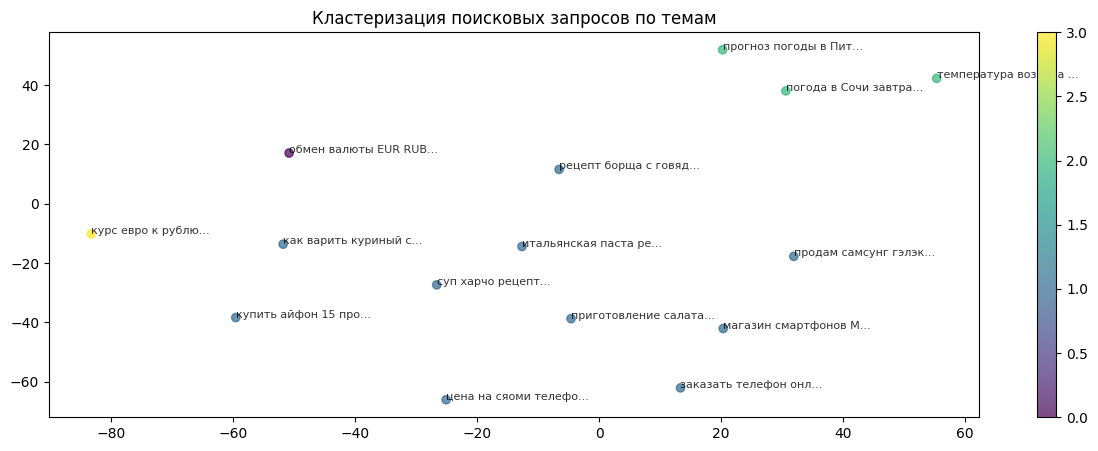

In [ ]:
analyzer.visualize_clusters(queries, clusters, embeddings)

In [ ]:
en_queries = [
    "purchase cheap iphone",
    "used mobiles sale",
    "iphone price",
    "mushroom pizza recipe",
    "how to make pizza at home",
    "italian pizza recipe",
    "weather in Moscow today",
    "weather forecast in the capital",
    "dollar to ruble exchange rate",
    "currency exchange USD to RUR"
]

analyzer = QueryAnalyzer()
clusters, embeddings = analyzer.cluster_queries(en_queries, n_clusters = 4)

In [ ]:
print("=== КЛАСТЕРИЗАЦИЯ ПОИСКОВЫХ ЗАПРОСОВ ===\n")
cluster_groups = {}
for query, cluster in zip(en_queries, clusters):
    if cluster not in cluster_groups:
        cluster_groups[cluster] = []
    cluster_groups[cluster].append(query)

for cluster_id, cluster_queries in cluster_groups.items():
    print(f"Кластер {cluster_id + 1}:")
    for query in cluster_queries:
        print(f"  - {query}")
    print()

=== КЛАСТЕРИЗАЦИЯ ПОИСКОВЫХ ЗАПРОСОВ ===

Кластер 2:
  - purchase cheap iphone
  - used mobiles sale
  - iphone price
  - mushroom pizza recipe
  - italian pizza recipe

Кластер 4:
  - how to make pizza at home

Кластер 1:
  - weather in Moscow today
  - weather forecast in the capital

Кластер 3:
  - dollar to ruble exchange rate
  - currency exchange USD to RUR



## Пример 3. Обнаружение дубликатов

Задаем класс

In [ ]:
class DuplicateDetector:
    def __init__(self, similarity_threshold=0.85):
        self.elmo = hub.load("https://tfhub.dev/google/elmo/3")
        self.threshold = similarity_threshold

    def find_duplicates(self, queries):
        """Поиск дубликатов и near-duplicate запросов"""
        embeddings = self._get_embeddings(queries)

        # Строим матрицу схожести
        similarity_matrix = cosine_similarity(embeddings)

        duplicates = []
        processed = set()

        for i in range(len(queries)):
            if i in processed:
                continue

            duplicate_group = [queries[i]]
            for j in range(i + 1, len(queries)):
                if similarity_matrix[i][j] > self.threshold:
                    duplicate_group.append(queries[j])
                    processed.add(j)

            if len(duplicate_group) > 1:
                duplicates.append(duplicate_group)

        return duplicates

    def _get_embeddings(self, texts):
        """Получение эмбеддингов для списка текстов"""
        embeddings = []
        inputs = tf.constant(texts)
        outputs = self.elmo.signatures["default"](inputs)
        token_embeddings = outputs["elmo"].numpy()
        sentence_embeddings = np.mean(token_embeddings, axis=1)
        return sentence_embeddings

Пример использования

In [ ]:
search_queries = [
    "купить айфон",
    "приобрести iPhone",
    "покупка телефона Apple",
    "купить яблочный телефон",
    "рецепт пирога с яблоками",
    "яблочный пирог рецепт",
    "погода в москве",
    "московская погода сегодня",
    "курс доллара",
    "доллар к рублю"
]

detector = DuplicateDetector(similarity_threshold = 0.8)
duplicate_groups = detector.find_duplicates(search_queries)

In [ ]:
print("=== ОБНАРУЖЕНИЕ ДУБЛИКАТОВ ЗАПРОСОВ ===\n")
for i, group in enumerate(duplicate_groups, 1):
    print(f"Группа дубликатов {i}:")
    for query in group:
        print(f"  - {query}")
    print()

=== ОБНАРУЖЕНИЕ ДУБЛИКАТОВ ЗАПРОСОВ ===

Группа дубликатов 1:
  - купить айфон
  - купить яблочный телефон

Группа дубликатов 2:
  - рецепт пирога с яблоками
  - яблочный пирог рецепт

Группа дубликатов 3:
  - погода в москве
  - московская погода сегодня



## Пример 4. Расширение поисковых запросов

Задаем класс

In [ ]:
class QueryExpander:
    def __init__(self):
        self.elmo = hub.load("https://tfhub.dev/google/elmo/3")

    def expand_query(self, query, candidate_queries, top_k=3):
        """Расширение поискового запроса похожими запросами"""
        all_queries = [query] + candidate_queries
        embeddings = self._get_embeddings(all_queries)

        query_embedding = embeddings[0]
        candidate_embeddings = embeddings[1:]

        similarities = cosine_similarity([query_embedding], candidate_embeddings)[0]

        # Выбираем самые похожие запросы
        expanded = []
        for i, sim in enumerate(similarities):
            expanded.append((candidate_queries[i], sim))

        expanded.sort(key=lambda x: x[1], reverse=True)
        return expanded[:top_k]

    def _get_embeddings(self, texts):
        """Получение эмбеддингов для списка текстов"""
        embeddings = []
        inputs = tf.constant(texts)
        outputs = self.elmo.signatures["default"](inputs)
        token_embeddings = outputs["elmo"].numpy()
        sentence_embeddings = np.mean(token_embeddings, axis=1)
        return sentence_embeddings

Пример использования

In [ ]:
expander = QueryExpander()

base_query = "купить смартфон"

candidate_queries = [
    "приобрести телефон",
    "продажа мобильных",
    "цена на айфон",
    "рейтинг смартфонов",
    "отзывы о телефонах",
    "магазин электроники",
    "интернет магазин техники",
    "доставка смартфонов"
]

expanded_queries = expander.expand_query(base_query, candidate_queries)

In [ ]:
print("=== РАСШИРЕНИЕ ПОИСКОВОГО ЗАПРОСА ===\n")
print(f"Исходный запрос: '{base_query}'")
print("Рекомендуемые расширения:")
for i, (exp_query, similarity) in enumerate(expanded_queries, 1):
    print(f"  {i}. {exp_query} (схожесть: {similarity:.4f})")

=== РАСШИРЕНИЕ ПОИСКОВОГО ЗАПРОСА ===

Исходный запрос: 'купить смартфон'
Рекомендуемые расширения:
  1. рейтинг смартфонов (схожесть: 0.8174)
  2. интернет магазин техники (схожесть: 0.7833)
  3. доставка смартфонов (схожесть: 0.7650)
